# EDA Assignment 2 – House Price Analysis and Feature Exploration
Datasets: Ames Housing, California Housing, House Sales in King County

Pipeline: load original data → clean → analyse & visualise (pandas, matplotlib, seaborn) → model → feature importance.

Expected files in the same folder: `ames_original.csv`, `king_county_original.csv`, `california_original.csv`.

In [1]:
import pandas as pd, numpy as np, re, warnings
import matplotlib.pyplot as plt, seaborn as sns
from matplotlib.ticker import FuncFormatter
warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
usd = FuncFormatter(lambda x,_: f'${x/1e3:,.0f}k')
pd.set_option('display.max_columns', 40)

## 1. Load original data

In [2]:
ames_raw = pd.read_csv('ames_original.csv')
kc_raw   = pd.read_csv('king_county_original.csv')
ca_raw   = pd.read_csv('california_original.csv')
for n,d in [('Ames',ames_raw),('King County',kc_raw),('California',ca_raw)]:
    print(f'{n:12s} shape={d.shape}  missing cells={int(d.isna().sum().sum())}  duplicates={int(d.duplicated().sum())}')

Ames         shape=(2930, 82)  missing cells=15749  duplicates=0
King County  shape=(21613, 21)  missing cells=0  duplicates=0
California   shape=(20640, 10)  missing cells=207  duplicates=0


In [3]:
miss = ames_raw.isna().sum(); print('Ames columns with missing values:'); print(miss[miss>0].sort_values(ascending=False).head(12))
print(); print('California missing:', ca_raw.isna().sum()[lambda s:s>0].to_dict())
print('King County bedrooms max:', kc_raw.bedrooms.max(), '| rows with 0 bathrooms:', int((kc_raw.bathrooms==0).sum()))

Ames columns with missing values:
Pool QC          2917
Misc Feature     2824
Alley            2732
Fence            2358
Mas Vnr Type     1775
Fireplace Qu     1422
Lot Frontage      490
Garage Qual       159
Garage Cond       159
Garage Yr Blt     159
Garage Finish     159
Garage Type       157
dtype: int64

California missing: {'total_bedrooms': 207}
King County bedrooms max: 33 | rows with 0 bathrooms: 10


## 2. Data cleaning
**Ames** – `NA` in Alley, Pool QC, Fence, basement and garage quality columns means *feature absent* → `'None'`; numeric gaps → 0; Lot Frontage → neighbourhood median; remove >4,000 sq ft outliers.

**King County** – fix 33-bedroom typo, drop rows with 0 bathrooms, parse dates.

**California** – impute `total_bedrooms`, flag the capped values, drop implausible blocks.

In [4]:
# ---------- Ames ----------
a = ames_raw.copy()
a.columns = [re.sub(r'[^0-9a-z]+','_',c.lower()).strip('_') for c in a.columns]
a = a.drop_duplicates()
none_cols = ['alley','mas_vnr_type','bsmt_qual','bsmt_cond','bsmt_exposure','bsmtfin_type_1','bsmtfin_type_2',
             'fireplace_qu','garage_type','garage_finish','garage_qual','garage_cond','pool_qc','fence','misc_feature']
for c in none_cols: a[c] = a[c].fillna('None')
for c in ['mas_vnr_area','bsmtfin_sf_1','bsmtfin_sf_2','bsmt_unf_sf','total_bsmt_sf','bsmt_full_bath','bsmt_half_bath','garage_cars','garage_area']:
    a[c] = a[c].fillna(0)
a['lot_frontage_missing'] = a.lot_frontage.isna().astype(int)
a['lot_frontage'] = a.groupby('neighborhood').lot_frontage.transform(lambda s: s.fillna(s.median()))
a['lot_frontage'] = a.lot_frontage.fillna(a.lot_frontage.median())
a['garage_yr_blt'] = a.garage_yr_blt.fillna(a.year_built)
a.loc[a.garage_yr_blt>2010,'garage_yr_blt'] = a.year_built
a['electrical'] = a.electrical.fillna(a.electrical.mode()[0])
a = a[a.gr_liv_area <= 4000]
a['house_age'] = a.yr_sold - a.year_built
a['years_since_remodel'] = a.yr_sold - a.year_remod_add
a['total_sf'] = a.total_bsmt_sf + a['1st_flr_sf'] + a['2nd_flr_sf']
a['total_bath'] = a.full_bath + .5*a.half_bath + a.bsmt_full_bath + .5*a.bsmt_half_bath
a['has_pool'] = (a.pool_qc!='None').astype(int); a['has_garage'] = (a.garage_type!='None').astype(int)
a['has_fireplace'] = (a.fireplaces>0).astype(int); a['has_basement'] = (a.total_bsmt_sf>0).astype(int)
a['log_saleprice'] = np.log1p(a.saleprice)

# ---------- King County ----------
k = kc_raw.drop_duplicates().copy()
k['date'] = pd.to_datetime(k.date, format='%Y%m%dT%H%M%S')
k.loc[k.bedrooms==33,'bedrooms'] = 3
k = k[(k.bathrooms>0)]
k['zipcode'] = k.zipcode.astype(str)
k['sale_year'] = k.date.dt.year; k['sale_month'] = k.date.dt.month
k['renovated'] = (k.yr_renovated>0).astype(int)
k['house_age'] = k.sale_year - k.yr_built
k['years_since_reno'] = np.where(k.renovated==1, k.sale_year-k.yr_renovated, k.house_age)
k['has_basement'] = (k.sqft_basement>0).astype(int)
k['price_per_sqft'] = (k.price/k.sqft_living).round(2)
k['repeat_sale'] = k.duplicated('id', keep=False).astype(int)
k['log_price'] = np.log(k.price)

# ---------- California ----------
c = ca_raw.drop_duplicates().copy()
c['total_bedrooms_missing'] = c.total_bedrooms.isna().astype(int)
c['total_bedrooms'] = c.total_bedrooms.fillna((c.total_rooms*(c.total_bedrooms/c.total_rooms).median()).round())
c['price_capped'] = (c.median_house_value>=500001).astype(int)
c['age_capped'] = (c.housing_median_age>=52).astype(int)
c['income_capped'] = (c.median_income>=15).astype(int)
c['rooms_per_household'] = c.total_rooms/c.households
c['bedrooms_per_room'] = c.total_bedrooms/c.total_rooms
c['population_per_household'] = c.population/c.households
c = c[(c.rooms_per_household<=20)&(c.population_per_household<=20)&(c.bedrooms_per_room<=1)]
c['log_median_house_value'] = np.log(c.median_house_value)

summary = pd.DataFrame({'rows_before':[len(ames_raw),len(kc_raw),len(ca_raw)],'rows_after':[len(a),len(k),len(c)],
    'cols_before':[ames_raw.shape[1],kc_raw.shape[1],ca_raw.shape[1]],'cols_after':[a.shape[1],k.shape[1],c.shape[1]],
    'missing_after':[int(a.isna().sum().sum()),int(k.isna().sum().sum()),int(c.isna().sum().sum())]},
    index=['Ames','King County','California'])
summary

,rows_before,rows_after,cols_before,cols_after,missing_after
Ames,2930,2925,82,92,0
King County,21613,21603,21,30,0
California,20640,20561,10,18,0


## 3. Exploratory analysis & visualisation
### 3.1 Target distributions

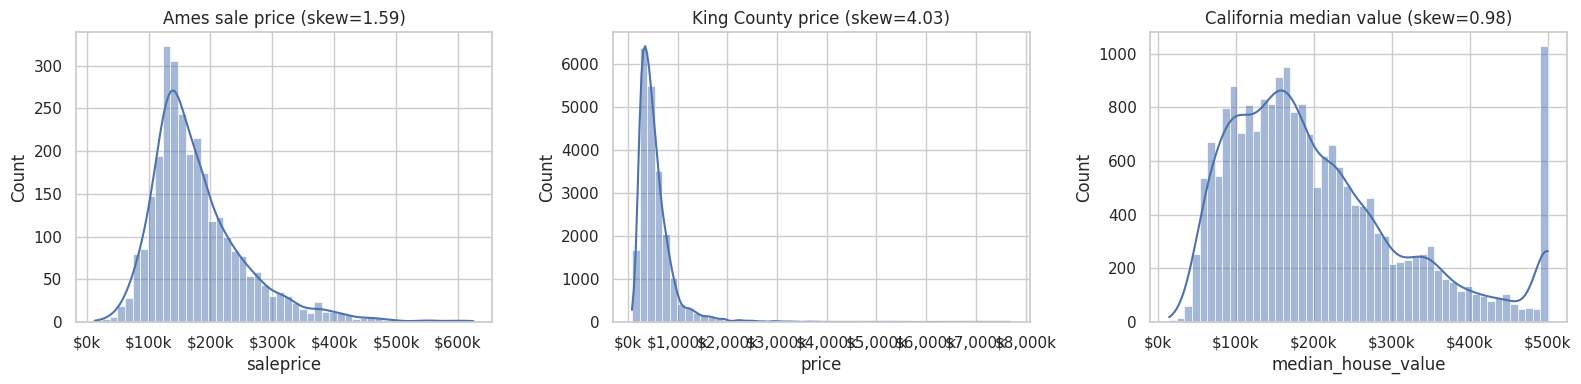

Skew after log: -0.04 0.43 -0.18


In [5]:
fig,ax = plt.subplots(1,3,figsize=(16,4))
for x,col,t in [(ax[0],a.saleprice,'Ames sale price'),(ax[1],k.price,'King County price'),(ax[2],c.median_house_value,'California median value')]:
    sns.histplot(col,bins=50,kde=True,ax=x); x.xaxis.set_major_formatter(usd); x.set_title(f'{t} (skew={col.skew():.2f})')
plt.tight_layout(); plt.show()
print('Skew after log:', round(a.log_saleprice.skew(),2), round(k.log_price.skew(),2), round(c.log_median_house_value.skew(),2))

### 3.2 Correlation with price

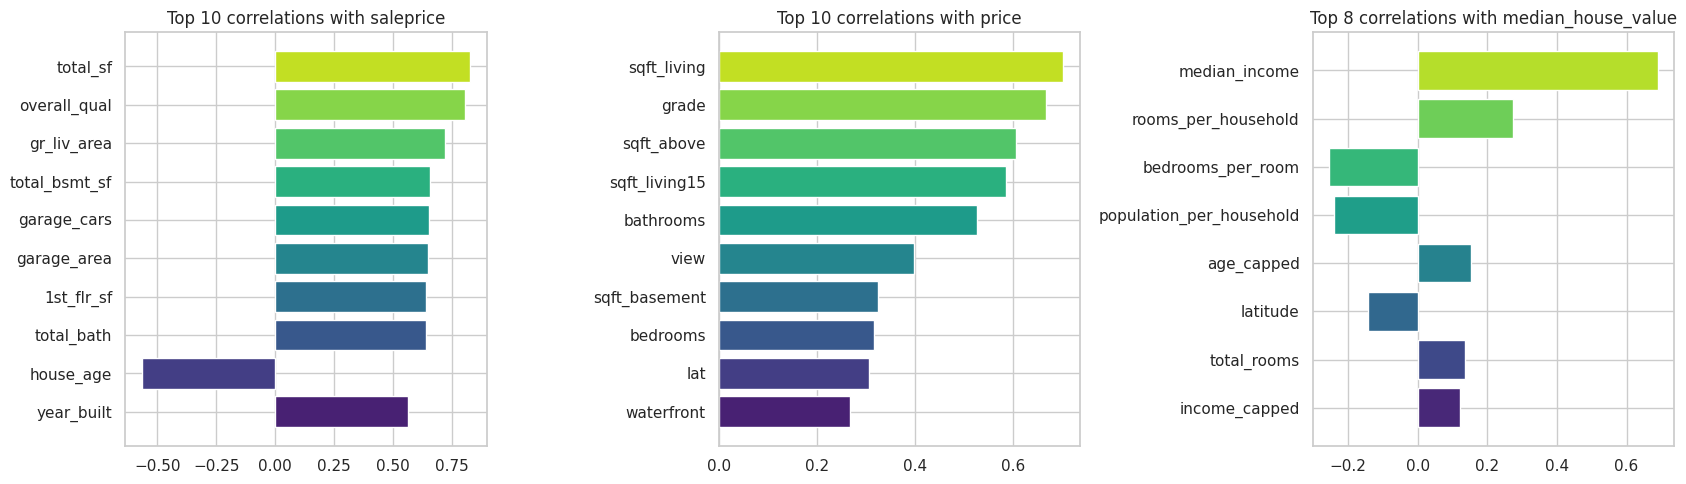

In [6]:
def corr_bar(ax, df, target, n=10, drop=()):
    s = df.select_dtypes('number').corr()[target].drop([target,*drop], errors='ignore')
    s = s.drop([i for i in s.index if 'log' in i])
    s = s.reindex(s.abs().sort_values(ascending=False).index[:n])[::-1]
    ax.barh(s.index, s.values, color=sns.color_palette('viridis', n)); ax.set_title(f'Top {n} correlations with {target}')
fig,ax = plt.subplots(1,3,figsize=(17,5))
corr_bar(ax[0],a,'saleprice'); corr_bar(ax[1],k,'price',drop=['price_per_sqft']); corr_bar(ax[2],c,'median_house_value',8,drop=['price_capped'])
plt.tight_layout(); plt.show()

### 3.3 Ames – quality, size and neighbourhood

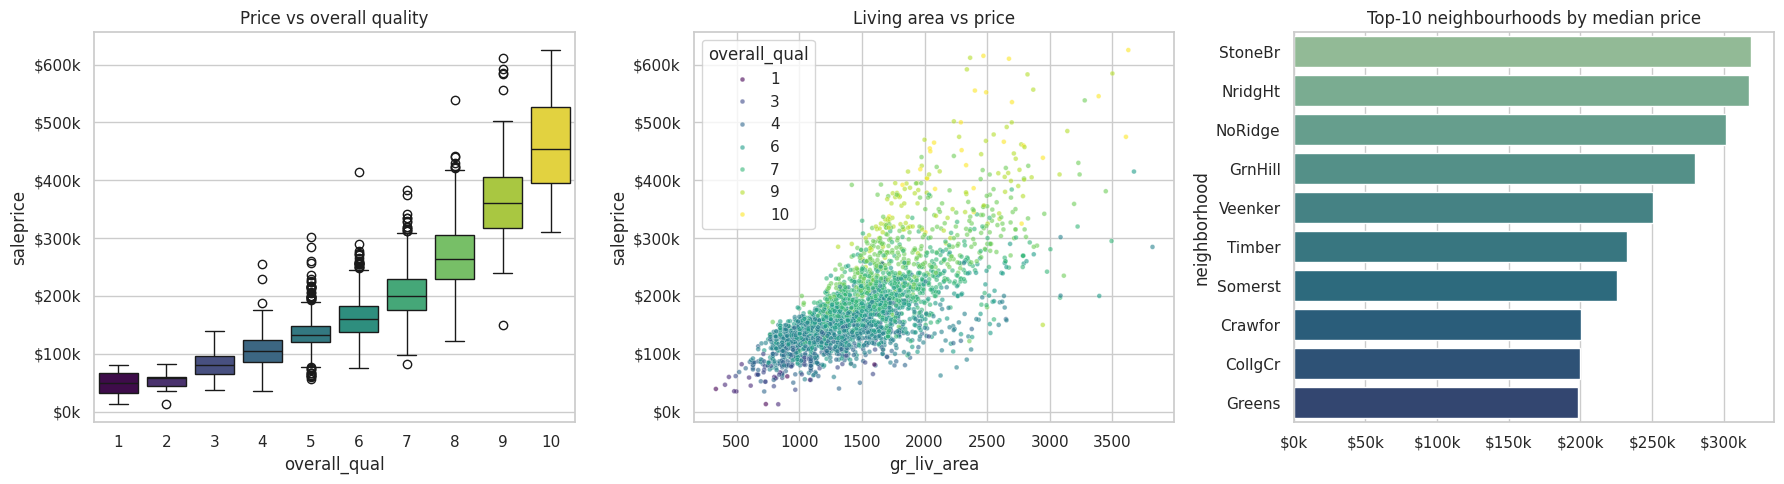

In [7]:
fig,ax = plt.subplots(1,3,figsize=(18,5))
sns.boxplot(data=a,x='overall_qual',y='saleprice',hue='overall_qual',palette='viridis',legend=False,ax=ax[0]); ax[0].yaxis.set_major_formatter(usd); ax[0].set_title('Price vs overall quality')
sns.scatterplot(data=a,x='gr_liv_area',y='saleprice',hue='overall_qual',palette='viridis',s=12,alpha=.6,ax=ax[1]); ax[1].yaxis.set_major_formatter(usd); ax[1].set_title('Living area vs price')
o = a.groupby('neighborhood').saleprice.median().sort_values(ascending=False).head(10)
sns.barplot(x=o.values,y=o.index,hue=o.index,palette='crest',legend=False,ax=ax[2]); ax[2].xaxis.set_major_formatter(usd); ax[2].set_title('Top-10 neighbourhoods by median price')
plt.tight_layout(); plt.show()

### 3.4 King County – grade, waterfront, location, time

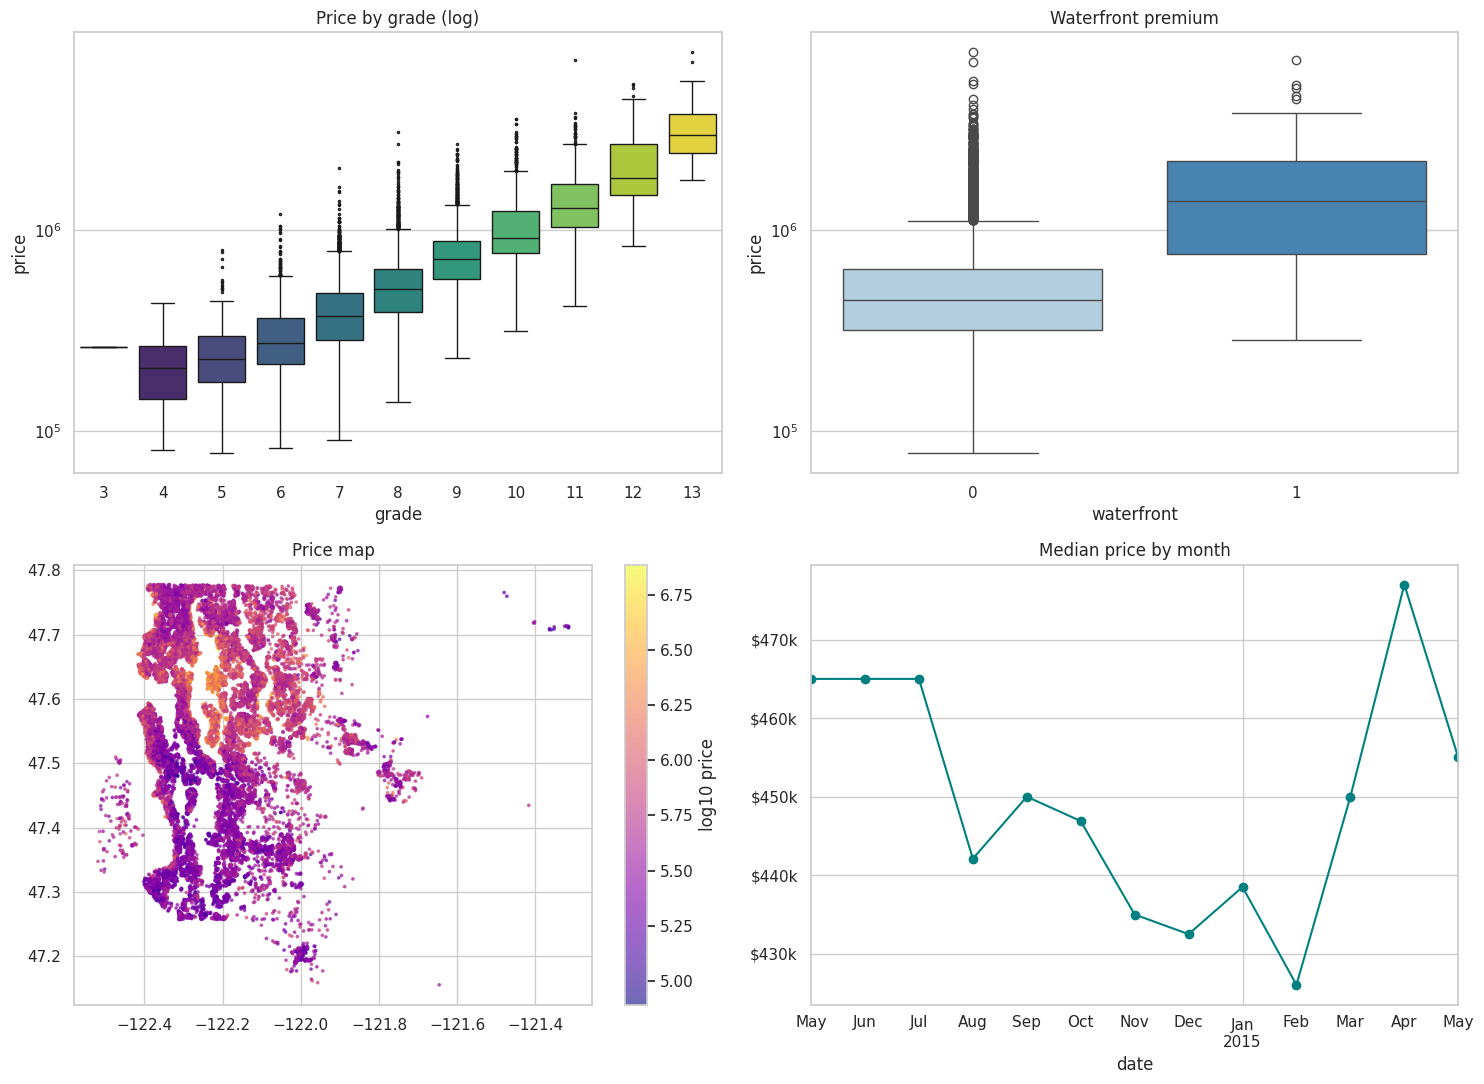

Waterfront / non-waterfront median ratio: 3.11


In [8]:
fig,ax = plt.subplots(2,2,figsize=(15,11))
sns.boxplot(data=k,x='grade',y='price',hue='grade',palette='viridis',legend=False,fliersize=1.5,ax=ax[0,0]); ax[0,0].set_yscale('log'); ax[0,0].set_title('Price by grade (log)')
sns.boxplot(data=k,x='waterfront',y='price',hue='waterfront',palette='Blues',legend=False,ax=ax[0,1]); ax[0,1].set_yscale('log'); ax[0,1].set_title('Waterfront premium')
sc = ax[1,0].scatter(k.long,k.lat,c=np.log10(k.price),s=3,cmap='plasma',alpha=.6); plt.colorbar(sc,ax=ax[1,0],label='log10 price'); ax[1,0].set_title('Price map')
k.set_index('date').price.resample('MS').median().plot(ax=ax[1,1],marker='o',color='teal'); ax[1,1].yaxis.set_major_formatter(usd); ax[1,1].set_title('Median price by month')
plt.tight_layout(); plt.show()
print('Waterfront / non-waterfront median ratio:', round(k[k.waterfront==1].price.median()/k[k.waterfront==0].price.median(),2))

### 3.5 California – geography and income

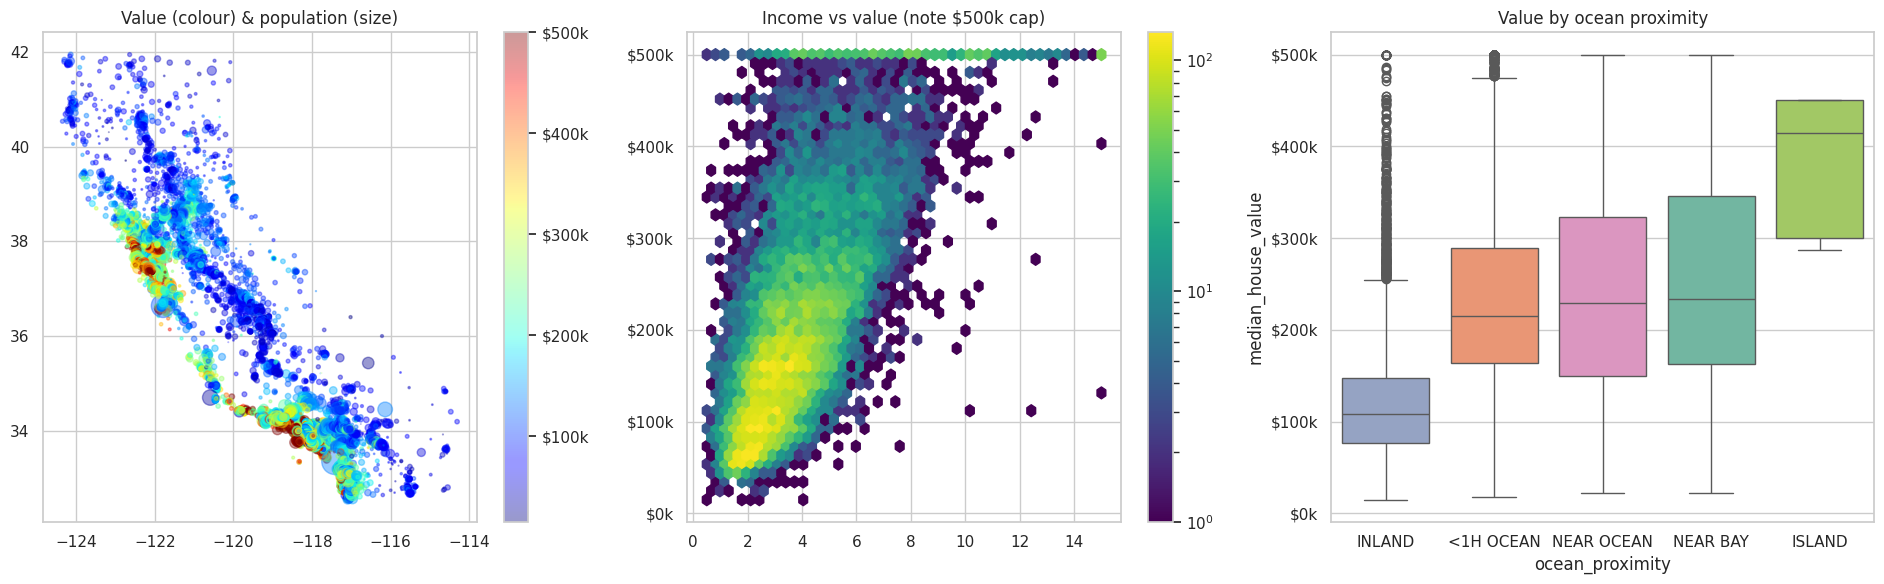

In [9]:
fig,ax = plt.subplots(1,3,figsize=(19,6))
s = ax[0].scatter(c.longitude,c.latitude,c=c.median_house_value,s=c.population/100,cmap='jet',alpha=.4); plt.colorbar(s,ax=ax[0],format=usd); ax[0].set_title('Value (colour) & population (size)')
h = ax[1].hexbin(c.median_income,c.median_house_value,gridsize=45,bins='log',cmap='viridis'); plt.colorbar(h,ax=ax[1]); ax[1].yaxis.set_major_formatter(usd); ax[1].set_title('Income vs value (note $500k cap)')
o = c.groupby('ocean_proximity').median_house_value.median().sort_values()
sns.boxplot(data=c,x='ocean_proximity',y='median_house_value',order=o.index,hue='ocean_proximity',palette='Set2',legend=False,ax=ax[2]); ax[2].yaxis.set_major_formatter(usd); ax[2].set_title('Value by ocean proximity')
plt.tight_layout(); plt.show()

### 3.6 Correlation heatmaps

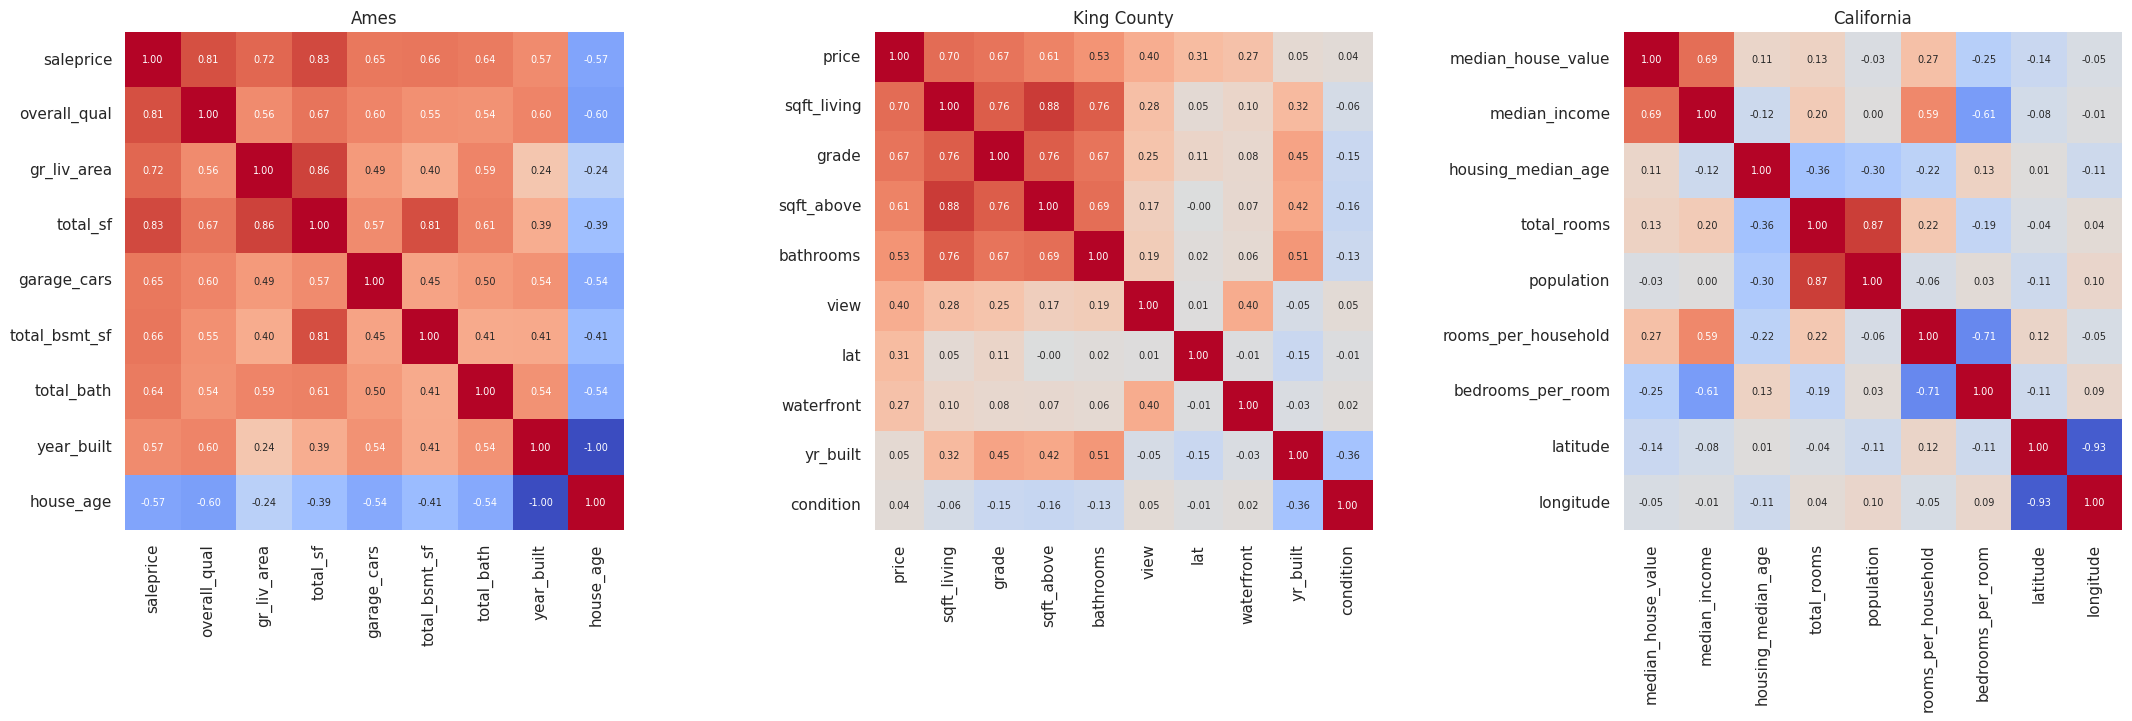

In [10]:
fig,ax = plt.subplots(1,3,figsize=(22,7))
for x,df,cols,t in [(ax[0],a,['saleprice','overall_qual','gr_liv_area','total_sf','garage_cars','total_bsmt_sf','total_bath','year_built','house_age'],'Ames'),
                    (ax[1],k,['price','sqft_living','grade','sqft_above','bathrooms','view','lat','waterfront','yr_built','condition'],'King County'),
                    (ax[2],c,['median_house_value','median_income','housing_median_age','total_rooms','population','rooms_per_household','bedrooms_per_room','latitude','longitude'],'California')]:
    sns.heatmap(df[cols].corr(),annot=True,fmt='.2f',cmap='coolwarm',center=0,square=True,cbar=False,ax=x,annot_kws={'size':7}); x.set_title(t)
plt.tight_layout(); plt.show()

## 4. Modelling
Target = log(price). Models: Linear Regression, Ridge, Random Forest, Gradient Boosting (80/20 split). Metrics are reported in dollars. The full 3-fold CV results used in the report are in `model_comparison.csv`.

In [11]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

cfg = {'Ames':(a,'log_saleprice',['saleprice','log_saleprice','order','pid']),
       'King County':(k,'log_price',['price','log_price','id','date','price_per_sqft']),
       'California':(c,'log_median_house_value',['median_house_value','log_median_house_value','price_capped'])}
results, importances = [], []
for name,(df,tgt,drop) in cfg.items():
    y = df[tgt]; X = df.drop(columns=drop)
    cat = X.select_dtypes(exclude='number').columns.tolist(); num = [x for x in X.columns if x not in cat]
    pre = lambda sc: ColumnTransformer([('c',OneHotEncoder(handle_unknown='ignore',min_frequency=10,sparse_output=False),cat),('n',StandardScaler() if sc else 'passthrough',num)])
    models = {'Linear Regression':(LinearRegression(),True),'Ridge (alpha=10)':(Ridge(alpha=10),True),
              'Random Forest':(RandomForestRegressor(n_estimators=80,min_samples_leaf=3,max_features=.4,n_jobs=-1,random_state=42),False),
              'Gradient Boosting':(HistGradientBoostingRegressor(max_iter=300,learning_rate=.08,random_state=42),False)}
    Xtr,Xte,ytr,yte = train_test_split(X,y,test_size=.2,random_state=42); best=(-9,None,None)
    for mn,(m,sc) in models.items():
        p = Pipeline([('p',pre(sc)),('m',m)]).fit(Xtr,ytr); pr = p.predict(Xte); r2 = r2_score(yte,pr)
        results.append(dict(dataset=name,model=mn,test_r2_log=round(r2,4),test_r2_dollars=round(r2_score(np.exp(yte),np.exp(pr)),4),
                            test_rmse=round(mean_squared_error(np.exp(yte),np.exp(pr))**.5),test_mae=round(mean_absolute_error(np.exp(yte),np.exp(pr)))))
        if r2>best[0]: best=(r2,p,mn)
    pi = permutation_importance(best[1],Xte,yte,n_repeats=3,random_state=42,scoring='r2')
    importances.append(pd.DataFrame({'dataset':name,'model':best[2],'feature':X.columns,'importance':pi.importances_mean}).sort_values('importance',ascending=False))
res = pd.DataFrame(results); res

,dataset,model,test_r2_log,test_r2_dollars,test_rmse,test_mae
0,Ames,Linear Regression,0.9531,0.9578,17326,12038
1,Ames,Ridge (alpha=10),0.9560,0.9585,17182,11748
2,Ames,Random Forest,0.9334,0.9329,21835,13512
3,Ames,Gradient Boosting,0.9411,0.9446,19838,12646
4,King County,Linear Regression,0.8797,0.6912,207264,78343
5,King County,Ridge (alpha=10),0.8783,0.6962,205558,79320
6,King County,Random Forest,0.8895,0.8581,140479,71543
7,King County,Gradient Boosting,0.9114,0.9059,114387,62832
8,California,Linear Regression,0.6907,0.5743,76205,48490
9,California,Ridge (alpha=10),0.6907,0.5743,76206,48496


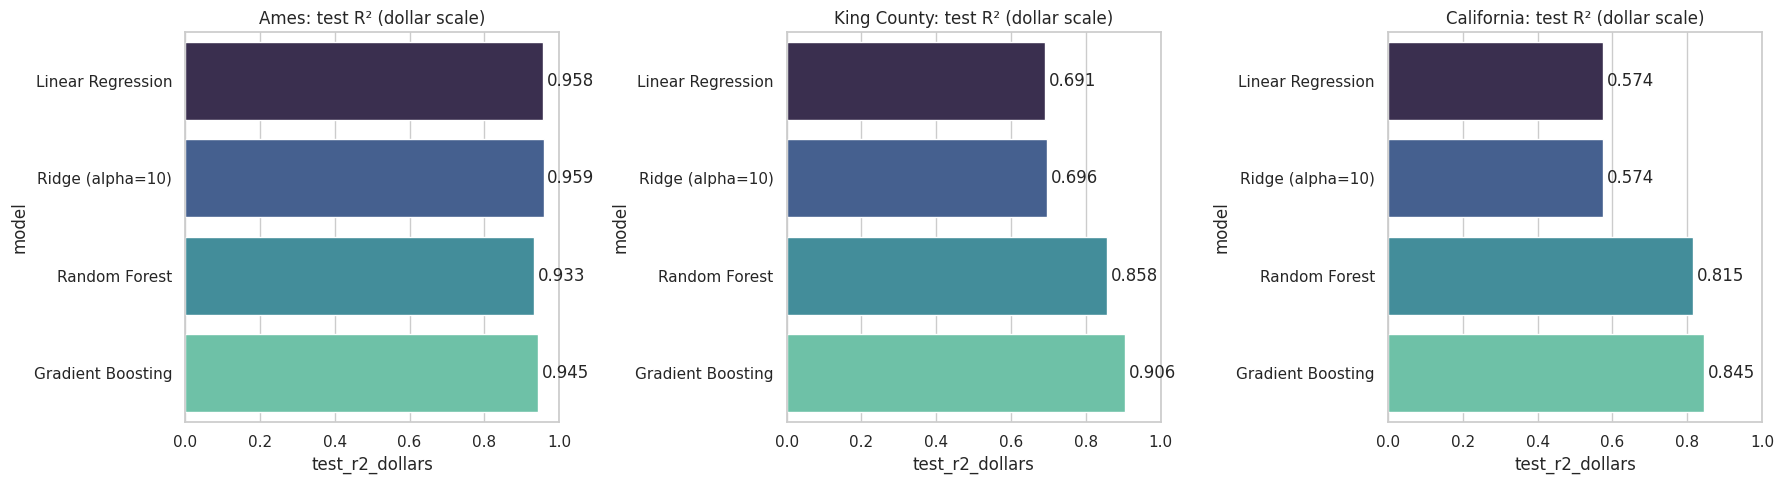

In [12]:
fig,ax = plt.subplots(1,3,figsize=(18,5))
for x,(name,g) in zip(ax,res.groupby('dataset',sort=False)):
    sns.barplot(data=g,x='test_r2_dollars',y='model',hue='model',palette='mako',legend=False,ax=x); x.set_xlim(0,1); x.set_title(f'{name}: test R² (dollar scale)')
    for i,v in enumerate(g.test_r2_dollars): x.text(v+.01,i,f'{v:.3f}',va='center')
plt.tight_layout(); plt.show()

## 5. Feature importance (permutation, best model per dataset)

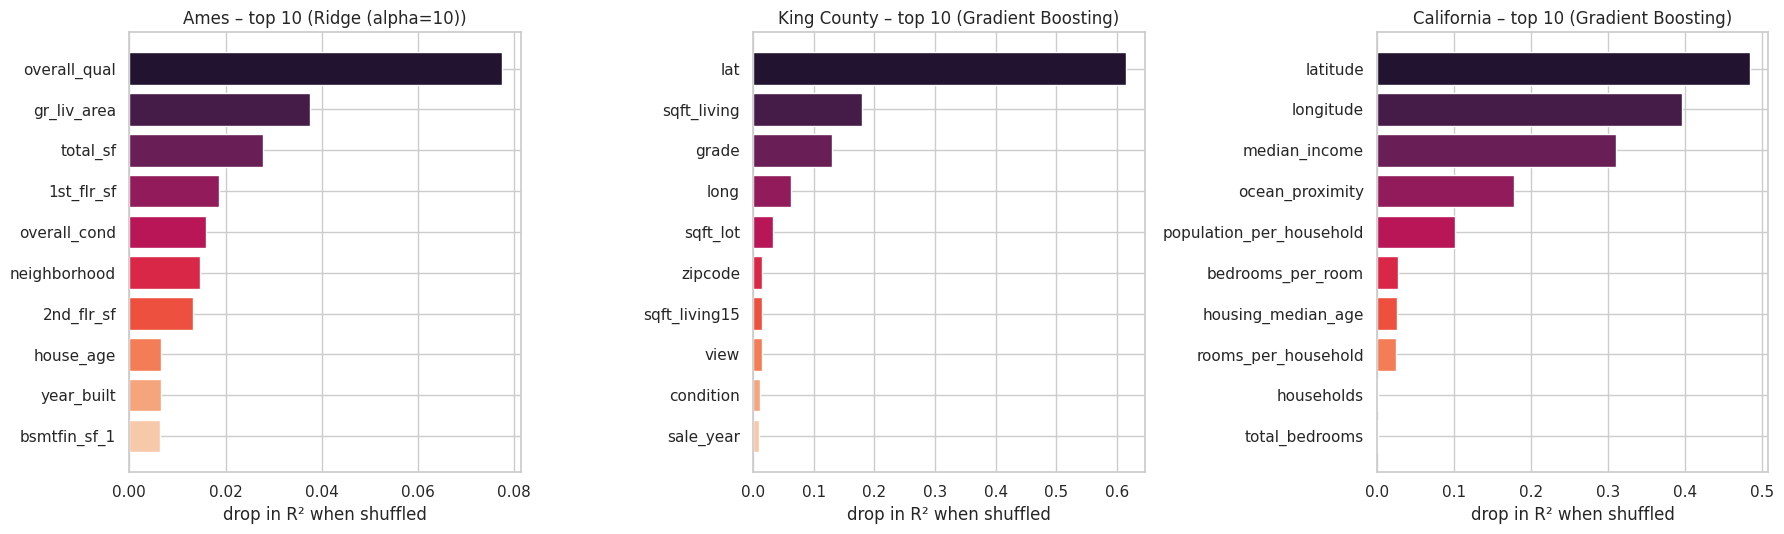

In [13]:
fi = pd.concat(importances)
fig,ax = plt.subplots(1,3,figsize=(18,5.5))
for x,(name,g) in zip(ax,fi.groupby('dataset',sort=False)):
    g = g.head(10)[::-1]; x.barh(g.feature,g.importance,color=sns.color_palette('rocket_r',10)); x.set_title(f'{name} – top 10 ({g.model.iloc[0]})'); x.set_xlabel('drop in R² when shuffled')
plt.tight_layout(); plt.show()

## 6. Key findings
* **Ames:** overall quality and living area (plus the engineered `total_sf`) dominate price; the linear/Ridge models beat tree models (R² ≈ 0.96), i.e. relationships are largely linear on the log scale.
* **King County:** location is the biggest driver – `lat` is the top feature – followed by living area and grade; waterfront homes sell at ≈ 3× the median. Gradient Boosting (R² ≈ 0.91) clearly beats linear models (≈ 0.69–0.70) because the location effect is non-linear.
* **California:** latitude/longitude and median income lead; non-linear models (R² ≈ 0.85) far outperform linear ones (≈ 0.57). The $500k price cap limits accuracy at the top end.
* **Lesson:** feature engineering and log-transforming the target help everywhere; tree-boosting wins when geography matters, regularised linear models win on the small, well-engineered Ames data.